# Assignment 04: Predicting Stroke Risks – Healthcare Data Pipeline

---

## Assignment Overview

**Domain:** Healthcare / Medical Diagnosis

**Objective:** Prepare a clean, processed, and analysis-ready dataset for stroke prediction. Your goal is to handle messy data, perform exploratory analysis, and apply preprocessing techniques to make the data ready for machine learning.

**Dataset:** Stroke Prediction Dataset from Kaggle

**Target Variable/Column:** `stroke` (0 = No Stroke, 1 = Stroke)

---

## Part 1: Data Loading & Initial Inspection

### Task 1.1: Import Required Libraries

Import the following libraries:
- `pandas` as `pd`
- `numpy` as `np`
- `matplotlib.pyplot` as `plt`
- `seaborn` as `sns`

In [2]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

### Task 1.2: Load the Dataset

Load the `healthcare-dataset-stroke-data.csv` file into a pandas DataFrame named `df`.

**Note:** Make sure the dataset file is in the same directory as this notebook, or provide the correct path.

In [3]:
df = pd.read_csv("healthcare-dataset-stroke-data.csv")

### Task 1.3: Display First 5 Rows

Display the first 5 rows of the dataset to get a quick overview.

In [4]:
df.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


### Task 1.4: Dataset Information

Use `.info()` to identify:
- Data types of each column
- Number of non-null values
- Memory usage

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


### Task 1.5: Statistical Summary

Use `.describe()` to check statistical summaries of numerical columns.

In [6]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


---

## Part 2: Exploratory Data Analysis (EDA) & Visualization

### Task 2.1: Target Variable Analysis

Create a countplot for the `stroke` column to visualize the class distribution.

<Axes: xlabel='stroke', ylabel='count'>

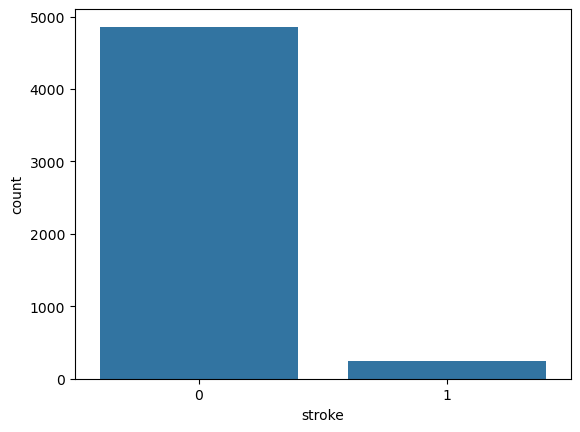

In [7]:
# Countplot for stroke variable
sns.countplot(data=df , x ='stroke' )

### Task 2.2: Categorical Features Visualization

Create countplots for the following categorical features, split by the target variable (use `hue='stroke'`):
1. `gender`
2. `work_type`
3. `smoking_status`

**Important:**
Plot them side by side. Use subplots to organize your visualizations.

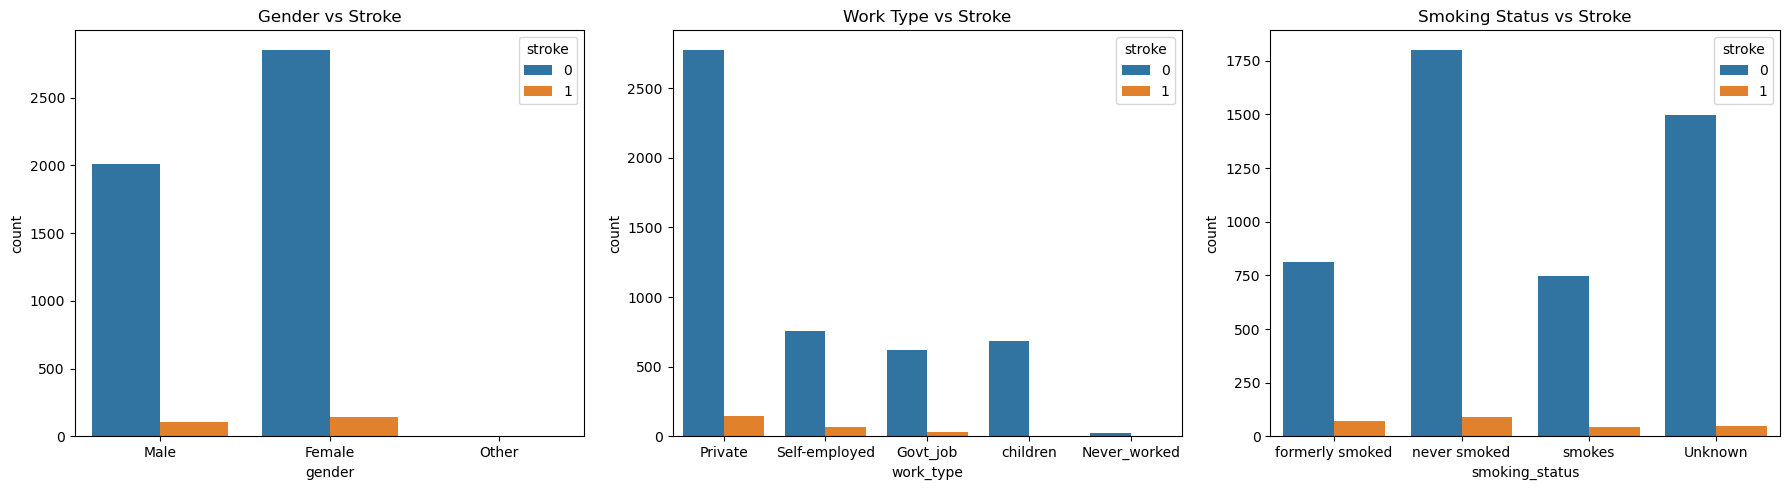

In [8]:
# Countplot for gender, work_type and smoking_status
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.countplot(data=df, x='gender', hue='stroke', ax=axes[0])
axes[0].set_title('Gender vs Stroke')
sns.countplot(data=df, x='work_type', hue='stroke', ax=axes[1])
axes[1].set_title('Work Type vs Stroke')
sns.countplot(data=df, x='smoking_status', hue='stroke', ax=axes[2])
axes[2].set_title('Smoking Status vs Stroke')
plt.tight_layout()
plt.show()



In [9]:
df.gender.value_counts()

gender
Female    2994
Male      2115
Other        1
Name: count, dtype: int64

In [10]:
# Suggested step: In gender column, As there's only one record with 'Other' value. We can drop it
df = df[df['gender']!='Other']


In [11]:
df['gender'].value_counts()

gender
Female    2994
Male      2115
Name: count, dtype: int64

**Your Observations:** (Optional)
- What patterns do you notice in these categorical features?
- Which categories seem to have higher stroke rates?

In [12]:
"""

"""

'\n\n'

### Task 2.3: Numerical Distributions

Create histograms or KDE plots for the following numerical features:
1. `age`
2. `avg_glucose_level`
3. `bmi`

**Important:**
Plot them side by side. Use subplots to organize your visualizations.

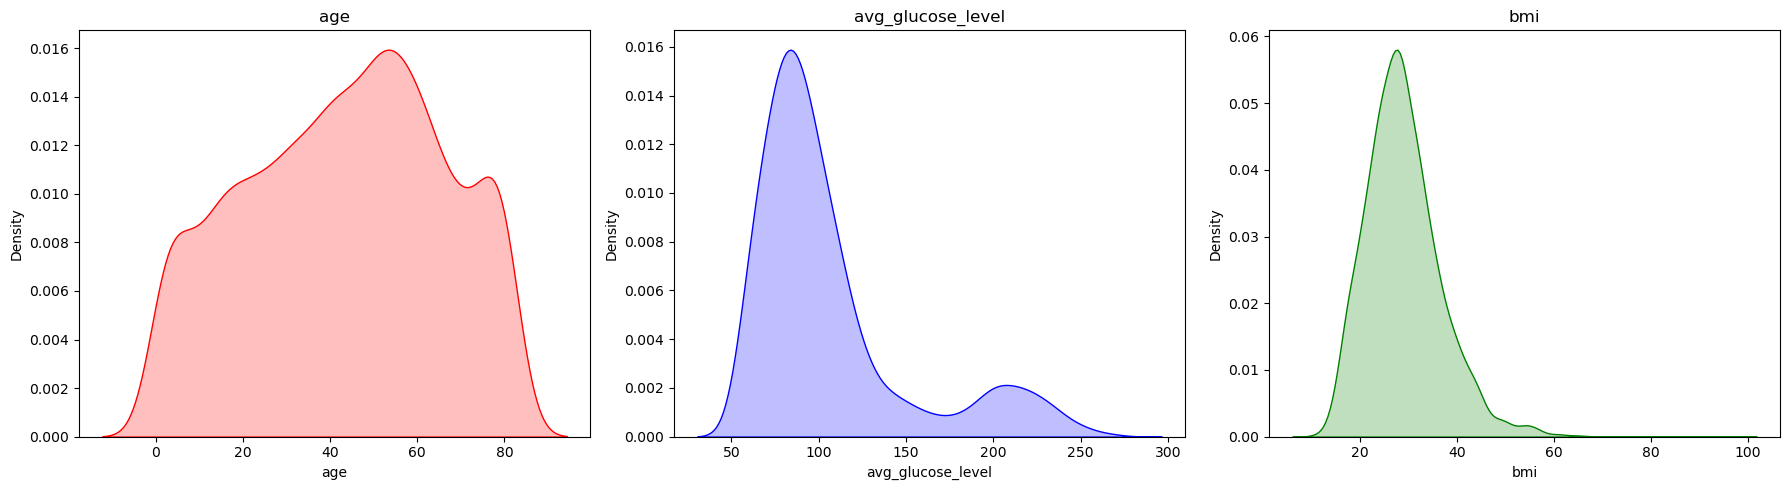

In [13]:
# Histogram for age, avg_glucose_level and bmi
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.kdeplot(df.age, color='red',fill=True,ax=axes[0])
axes[0].set_title('age')
sns.kdeplot(df.avg_glucose_level, color='blue',fill=True,ax=axes[1])
axes[1].set_title('avg_glucose_level')
sns.kdeplot(df.bmi, color='green',fill=True,ax=axes[2])
axes[2].set_title('bmi')
plt.tight_layout()
plt.show()




### Task 2.4: Correlation Analysis

Create a heatmap to show the correlation between numerical variables.

Select only numerical columns: `age`, `hypertension`, `heart_disease`, `avg_glucose_level`, `bmi`, and `stroke`.

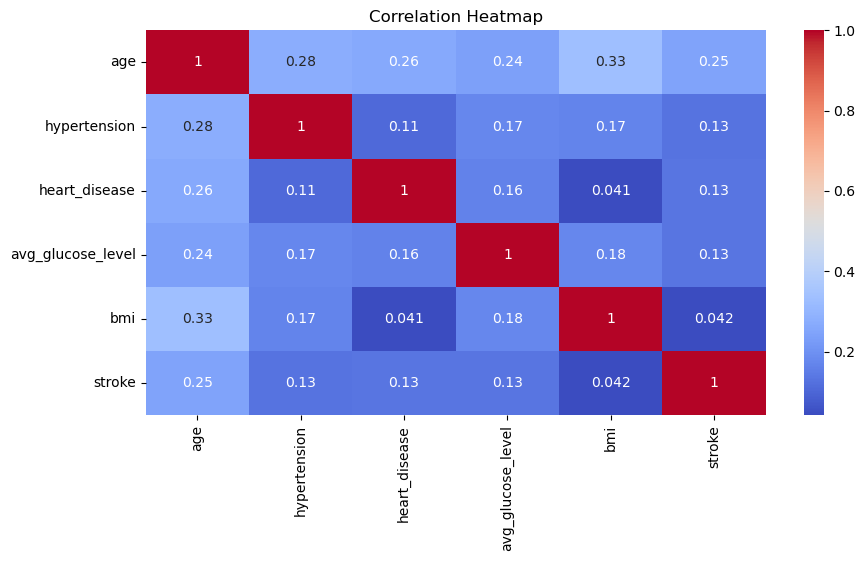

In [14]:
# Select features
numeric_col = ['age','hypertension','heart_disease','avg_glucose_level','bmi','stroke']
# Correlation heatmap
correlation = df[numeric_col].corr()

plt.figure(figsize=(10,5))
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

**Your Observations:** (Optional)
- Which features show the strongest correlation with stroke?

In [15]:
"""

"""

'\n\n'

---

## Part 3: Data Preprocessing (Cleaning)

### Task 3.1: Handling Missing Values

Check for missing values in the dataset and identify which columns have them.

In [16]:
# Check for missing values
df.isnull().sum()

id                     0
gender                 0
age                    0
hypertension           0
heart_disease          0
ever_married           0
work_type              0
Residence_type         0
avg_glucose_level      0
bmi                  201
smoking_status         0
stroke                 0
dtype: int64

**Task:** Fill the missing values in the `bmi` column using either the mean or median.

In [17]:
# Fill missing values in bmi
df.bmi.fillna(df.bmi.median(),inplace=True)

In [18]:
df

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,28.1,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


In [19]:
# Verify no missing values remain
df.isnull().sum()

id                   0
gender               0
age                  0
hypertension         0
heart_disease        0
ever_married         0
work_type            0
Residence_type       0
avg_glucose_level    0
bmi                  0
smoking_status       0
stroke               0
dtype: int64

### Task 3.2: Handling Duplicates

Check for duplicate rows and remove them if any exist.

In [20]:
# Check for duplicates
df.duplicated().sum()

np.int64(0)

In [21]:
# Remove duplicates if any
###### No duplicates found

### Task 3.3: Remove Irrelevant Columns

Drop the `id` column as it has no predictive power.

In [22]:
# Drop the id column
df.drop(columns=['id'],inplace=True)

In [23]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [24]:
df.duplicated().sum()

np.int64(0)

### Task 3.4: Outlier Detection

Use a boxplot to visualize outliers in `avg_glucose_level`.

<Axes: xlabel='avg_glucose_level'>

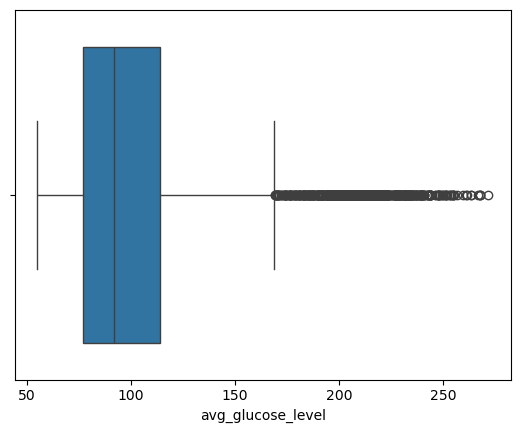

In [25]:
# Boxplot for avg_glucose_level
sns.boxplot(x='avg_glucose_level',data=df)

In [26]:
df.avg_glucose_level.describe()

count    5109.000000
mean      106.140399
std        45.285004
min        55.120000
25%        77.240000
50%        91.880000
75%       114.090000
max       271.740000
Name: avg_glucose_level, dtype: float64

In [27]:
# Remove outliers if needed
Q1 = df.avg_glucose_level.quantile(0.25)
Q2 = df.avg_glucose_level.quantile(0.50)
Q3 = df.avg_glucose_level.quantile(0.75)
print(f'Q1 --> {Q1}')
print(f'Q2 --> {Q2}')
print(f'Q3 --> {Q3}')
print('-'*10)
IQR = Q3 - Q1
print(f'IQR --> {IQR}')
print('-'*10)
lower = Q1-1.5*IQR
upper = Q3+1.5*IQR
print(f'lower bound --> {lower}')
print(f'upper bound --> {upper}')

Q1 --> 77.24
Q2 --> 91.88
Q3 --> 114.09
----------
IQR --> 36.85000000000001
----------
lower bound --> 21.964999999999982
upper bound --> 169.365


In [28]:
outliers = df[(df.avg_glucose_level<lower)|(df.avg_glucose_level>upper)]

In [29]:
outliers

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.1,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
5,Male,81.0,0,0,Yes,Private,Urban,186.21,29.0,formerly smoked,1
...,...,...,...,...,...,...,...,...,...,...,...
5061,Male,41.0,0,0,Yes,Private,Urban,223.78,32.3,never smoked,0
5062,Female,82.0,0,0,Yes,Self-employed,Rural,211.58,36.9,never smoked,0
5063,Male,39.0,0,0,Yes,Private,Urban,179.38,27.7,Unknown,0
5064,Male,70.0,0,0,Yes,Self-employed,Rural,193.88,24.3,Unknown,0


In [30]:
df = df[(df.avg_glucose_level>=lower)&(df.avg_glucose_level<=upper)]

In [31]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
6,Male,74.0,1,1,Yes,Private,Rural,70.09,27.4,never smoked,1
7,Female,69.0,0,0,No,Private,Urban,94.39,22.8,never smoked,1
8,Female,59.0,0,0,Yes,Private,Rural,76.15,28.1,Unknown,1
9,Female,78.0,0,0,Yes,Private,Urban,58.57,24.2,Unknown,1


In [32]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 4482 entries, 2 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             4482 non-null   object 
 1   age                4482 non-null   float64
 2   hypertension       4482 non-null   int64  
 3   heart_disease      4482 non-null   int64  
 4   ever_married       4482 non-null   object 
 5   work_type          4482 non-null   object 
 6   Residence_type     4482 non-null   object 
 7   avg_glucose_level  4482 non-null   float64
 8   bmi                4482 non-null   float64
 9   smoking_status     4482 non-null   object 
 10  stroke             4482 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 420.2+ KB


**Your Observations:** (Optional)
- Did you find outliers ?
- If found, should we remove them ? Why / Why not ?

In [33]:
"""

"""

'\n\n'

---

## Part 4: Data Splitting

### Task 4.1: Separate Features and Target

Separate your dataset into:
- `X`: All features (independent variables)
- `y`: Target variable (`stroke`)

In [34]:
# Separate features and target
x = df.drop(columns=['stroke'])
y = df.stroke

### Task 4.2: Train-Test Split

Split the data into training (80%) and testing (20%) sets using `train_test_split` from sklearn.

Use `random_state=42` for reproducibility.

In [35]:
# Import train_test_split
from sklearn.model_selection import train_test_split

In [36]:
# Split the data
x_train, x_test ,y_train,y_test= train_test_split(x,y,test_size=0.2,random_state=42)

### Task 4.3: Verify Split Shapes

Print the shapes of `X_train`, `X_test`, `y_train`, and `y_test` to verify the split.

In [37]:
# Print shapes
print(f'x_train --> {x_train.shape}')
print(f'y_train --> {y_train.shape}')
print(f'x_test --> {x_test.shape}')
print(f'y_test --> {y_test.shape}')



x_train --> (3585, 10)
y_train --> (3585,)
x_test --> (897, 10)
y_test --> (897,)


---
## Part 5: Feature Transformation

### Task 5.1: Encoding

Apply Encoding to the following categorical variables:
- `gender`
- `work_type`
- `smoking_status`
- `ever_married`
- `Residence_type`

For each feature, check if it's an **Ordinal** or **Nominal**, **Binary-Categorical** or **Multi-Categorical** Feature.  
Use the suitable encoder based on your obseravations.

In [38]:
df.gender.value_counts() #labelencoder

gender
Female    2665
Male      1817
Name: count, dtype: int64

In [39]:
df.work_type.value_counts() #labelencoder

work_type
Private          2552
children          675
Self-employed     669
Govt_job          564
Never_worked       22
Name: count, dtype: int64

In [40]:
df.smoking_status.value_counts() #labelencoder

smoking_status
never smoked       1633
Unknown            1441
formerly smoked     723
smokes              685
Name: count, dtype: int64

In [41]:
df.ever_married.value_counts() #labelencoder

ever_married
Yes    2801
No     1681
Name: count, dtype: int64

In [42]:
df.Residence_type.value_counts() #labelencoder

Residence_type
Urban    2274
Rural    2208
Name: count, dtype: int64

In [43]:
# Encoding
from sklearn.preprocessing import OneHotEncoder

In [44]:
ohe = OneHotEncoder()

In [45]:
df.head()

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
6,Male,74.0,1,1,Yes,Private,Rural,70.09,27.4,never smoked,1
7,Female,69.0,0,0,No,Private,Urban,94.39,22.8,never smoked,1
8,Female,59.0,0,0,Yes,Private,Rural,76.15,28.1,Unknown,1
9,Female,78.0,0,0,Yes,Private,Urban,58.57,24.2,Unknown,1


In [62]:
# Encoding
x_train_enc = pd.DataFrame((ohe.fit_transform(x_train[['gender','work_type', 'smoking_status', 'ever_married','Residence_type']])).toarray(),
             columns=ohe.get_feature_names_out(['gender','work_type', 'smoking_status', 'ever_married','Residence_type']),
             index=x_train.index)


In [63]:

x_train_num = x_train.drop(columns=['gender', 'work_type', 'smoking_status','ever_married', 'Residence_type'])
x_train_final = pd.concat([x_train_num, x_train_enc], axis=1)


In [64]:
x_train_final.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,ever_married_No,ever_married_Yes,Residence_type_Rural,Residence_type_Urban
2567,48.0,0,0,57.43,53.5,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0
4847,30.0,0,0,84.92,47.8,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
159,81.0,1,0,74.02,25.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
26,65.0,0,0,100.98,28.2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0
2845,5.0,0,0,93.03,16.3,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0


In [65]:
x_test_enc = pd.DataFrame(
    ohe.transform(x_test[['gender','work_type','smoking_status','ever_married','Residence_type']]).toarray(),
    columns=ohe.get_feature_names_out(['gender','work_type','smoking_status','ever_married','Residence_type']),
    index=x_test.index
)


In [66]:
x_test_num = x_test.drop(columns=['gender', 'work_type', 'smoking_status', 
                                    'ever_married', 'Residence_type'])

x_test_final = pd.concat([x_test_num, x_test_enc], axis=1)

In [68]:
x_test_final.head()

,age,hypertension,heart_disease,avg_glucose_level,bmi,gender_Female,gender_Male,work_type_Govt_job,work_type_Never_worked,work_type_Private,work_type_Self-employed,work_type_children,smoking_status_Unknown,smoking_status_formerly smoked,smoking_status_never smoked,smoking_status_smokes,ever_married_No,ever_married_Yes,Residence_type_Rural,Residence_type_Urban
238,51.0,1,0,88.20,28.4,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
4537,51.0,0,0,81.38,34.1,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
1208,41.0,0,0,107.18,22.8,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0
1318,50.0,0,1,85.82,31.9,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
891,54.0,0,0,90.92,29.1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0


---

## Part 6: Feature Scaling

### Task 6.1: Scale Numerical Features

The features `age`, `avg_glucose_level`, and `bmi` have different scales.

Apply `StandardScaler` or `MinMaxScaler` to these three columns.

In [49]:
# Import scaler
from sklearn.preprocessing import MinMaxScaler

In [50]:
mms = MinMaxScaler()

In [51]:
# Apply scaling to age, avg_glucose_level, and bmi

mms_x_train= pd.DataFrame(mms.fit_transform(x_train[['age','avg_glucose_level','bmi']]),
             columns=['age','avg_glucose_level','bmi'])

In [52]:
mms_x_train.head()

,age,avg_glucose_level,bmi
0,0.584961,0.020342,0.494845
1,0.365234,0.262416,0.429553
2,0.987793,0.166432,0.168385
3,0.792480,0.403839,0.205040
4,0.060059,0.333832,0.068729


---

## Part 7: Handling Class Imbalance

### Task 7.1: Check Current Class Distribution

Display the value counts of the target variable before handling imbalance.

In [53]:
# Check current distribution
df.stroke.value_counts()

stroke
0    4317
1     165
Name: count, dtype: int64

<Axes: xlabel='stroke', ylabel='count'>

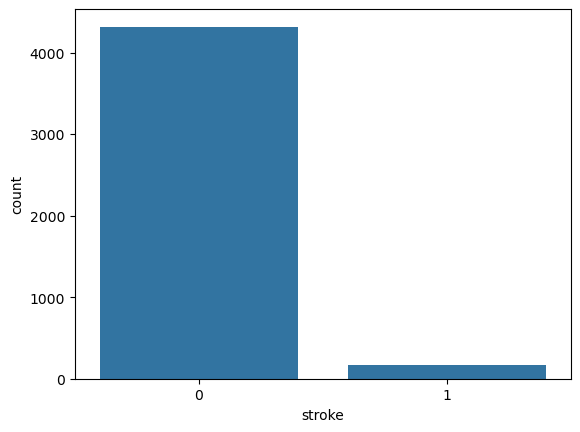

In [56]:
sns.countplot(x='stroke',data=df)

### Task 7.2: Handle Unbalanced Data

Apply oversampling, undersampling, or SMOTE to balance the dataset.

Import the appropriate method before applying it.

In [57]:
# Handle unbalanced data (choose your method)
from imblearn.over_sampling import SMOTE

In [58]:
smote =SMOTE(random_state=0)

In [69]:
x_train_smote,y_train_smote = smote.fit_resample(x_train_final,y_train)

### Task 7.3: Verify Class Balance

Check the value counts of the target variable after oversampling to ensure classes are balanced.

<Axes: xlabel='stroke', ylabel='count'>

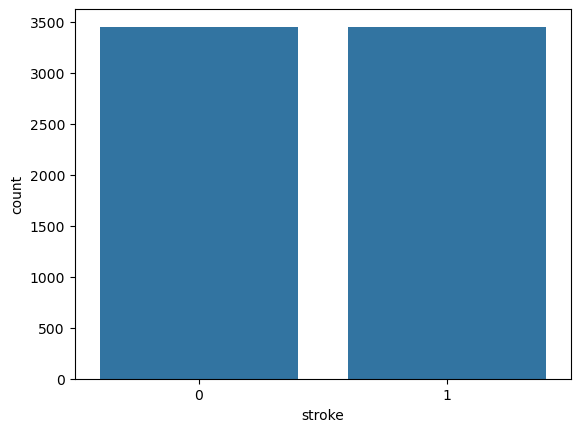

In [74]:
# Verify new distribution
sns.countplot(x=y_train_smote)

---

## Conclusion

### Task: High-Risk Stroke Patient Persona (Optional)

Based on your exploratory data analysis, write a short paragraph describing the **"persona" of a high-risk stroke patient**. Consider factors like age, glucose levels, work type, and medical history.

In [ ]:
"""
# Persona


# Summary


"""

**Good luck! 🎯**